# Lab 3 - Deep Learning
## Ava Everett (49136678) and Jay Lu (49200794)

## Deep Learning Framework. 
*Demonstrate conceptual understanding of a deep learning workflow. Without assistance from an LLM, explain the role of the following PyTorch components:*

- **Dataset (in Pytorch)**: An abstract class that represents the imported dataset. Argument of the DataLoader constructor; stores every sample from the data and its respective labels. There are two types of datasets: map-style datasets and iterable-style datasets. 
- **Data Loader**: A class that allows the program to iterate through a dataset in determined batches. It also provides the framework to use a variety of multiprocessing functions, and it can be used to train a model.
- **Model Class (nn.Module)**: The base class for all neural network modules; registers parameters and, if they have weights, will express them via instances of torch.nn.Parameter. Has an init and forward function for initialization and computation, respectively.
- **Loss Function**: Measure how well the model's predicted value is to the target value. Can be used to optimize output and gauge how well/poorly a model is doing. 
- **Optimizer**: A specific version of an optimization algorithm to update a neural network's parameters. There are a few available in PyTorch (e.g., Adam, Adagrad, SGD), but you can build your own custom optimizer for specific problems.
- **Training Loop (Providing Training Data to Model)**: Feeds the sample data to the model for the optimizer to tune the model's parameters. Works by grabbing a batch of data from the DataLoader, performs its predictions, calculates the loss on the predictions and the actual data, backpropagates, adjusts the model's learning weights based on the new observations, and reports the loss. It works in epochs, which are passes through the entire dataset, validating and saving a copy of the model each time. Model must be set to training mode during this time. 
- **Validation Loop (Providing Data to Evaluate the Model)**: Is inside the epoch loop, only does a forward pass and loss calculation (aka: no backprop). Helps with detection of overfitting, tuning hyperparameters, and letting the user see when is the best point to stop the training of the model. Model must be set to evaluation mode during this time. 

## Training Pipeline
*Using an LLM, generate starter code that constructs the training pipeline for your dataset and model. The pipeline should allow at least two ways of providing data to your model: (1) all data can be provided to a model as a single input and (2) modalities of data can be provided to the model as separate parallel inputs. When using an LLM, you should provide the prompt used, identify one aspect of the generated pipeline that was modified by your team, and explain why the modification was necessary.*

In [1]:
# importing dataset - Anime Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print ('Pandas:', pd.__version__)
print('Numpy:', np.__version__)

df = pd.read_csv('https://raw.githubusercontent.com/Lu-Rin-e/CS5324-Machine-Learning-Labs/refs/heads/main/anime_dataset_20k.csv')
df.head()

Pandas: 3.0.6
Numpy: 2.5.3


,mal_id,anilist_id,title_english,title_romaji,title_japanese,title_synonyms,type,source,status,age_rating,...,is_disney_plus,is_hulu,is_vrv,is_bilibili,is_youtube,num_platforms,score_tier,popularity_tier,synopsis,image_url
0,1,1.0,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,NaN,TV,original,finished_airing,r,...,False,True,False,False,False,6,Great,Top 100,"Crime is timeless. By the year 2071, humanity ...",https://cdn.myanimelist.net/images/anime/4/196...
1,5,5.0,Cowboy Bebop: The Movie,Cowboy Bebop: Tengoku no Tobira,カウボーイビバップ 天国の扉,Cowboy Bebop: Knockin' on Heaven's Door,MOVIE,original,finished_airing,r,...,False,False,False,False,False,0,Great,Top 1K,"Another day, another bounty—such is the life o...",https://cdn.myanimelist.net/images/anime/1439/...
2,6,6.0,Trigun,Trigun,トライガン,NaN,TV,manga,finished_airing,pg_13,...,False,False,False,False,False,1,Great,Top 500,"Vash the Stampede is the man with a $$60,000,0...",https://cdn.myanimelist.net/images/anime/1130/...
3,7,7.0,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),WHR,TV,original,finished_airing,pg_13,...,False,False,False,False,False,1,Good,Top 5K,"Though hidden away from the general public, Wi...",https://cdn.myanimelist.net/images/anime/10/19...
4,8,8.0,Beet the Vandel Buster,Bouken Ou Beet,冒険王ビィト,Adventure King Beet,TV,manga,finished_airing,pg,...,False,False,False,False,False,0,Average,Niche,It is the dark century and the people are suff...,https://cdn.myanimelist.net/images/anime/7/215...


Our main goal will be to get the model to accurately predict the popularity tier of a show (e.g., Niche, Top 5K, Top 1k, Top 500, and Top 100). 

Since just about all of the non tv/movies are niche, this set will isolate tv shows and movies. We will also remove all adult/explicit anime.

In [2]:
# Removing Adult/Explicit Anime
df = df[df.is_adult == False]

#Removing is_adult column
del df['is_adult']

# Removing all items that aren't TV shows or Movies
df = df[(df.type == 'TV') | (df.type == 'MOVIE')]

Let's see the split of the data

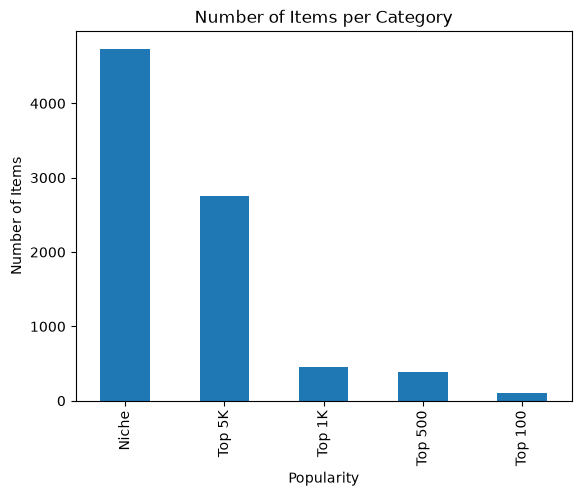

In [3]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

We'll be consolidating Top 1K, Top 500, and Top 100 into one category, as they are too small by themselves.

In [4]:
df['popularity_tier'] = df['popularity_tier'].replace('Top 100', 'Top 1K')
df['popularity_tier'] = df['popularity_tier'].replace('Top 500', 'Top 1K')

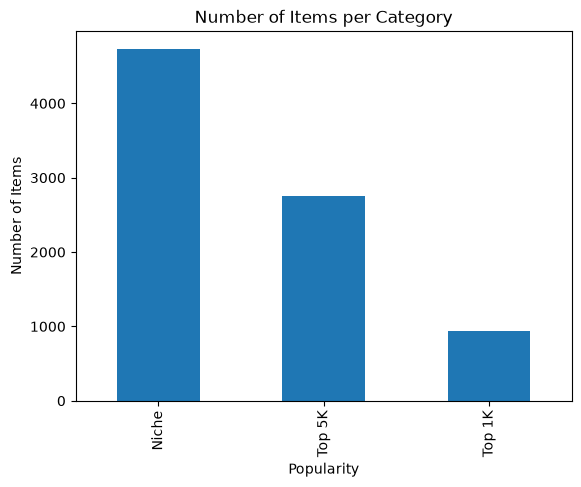

In [5]:
df['popularity_tier'].value_counts().plot(kind="bar")

plt.xlabel("Popularity")
plt.ylabel("Number of Items")
plt.title("Number of Items per Category")
plt.show()

With that settled, let's start cleaning up the data more. 

1 - As we're predicting popularity, all popularity-related categories must be removed to prevent data leaking (aka: MAL popularity, MAL members, MAL favorites, anilist popularity, anilist favorites). All non-relevant categories/difficult to parse categories will also be removed (ie: anime title, synopsis, etc.)
2 - We need to multi-hot encode the genres AND convert score_tier and popularity_tier to integers

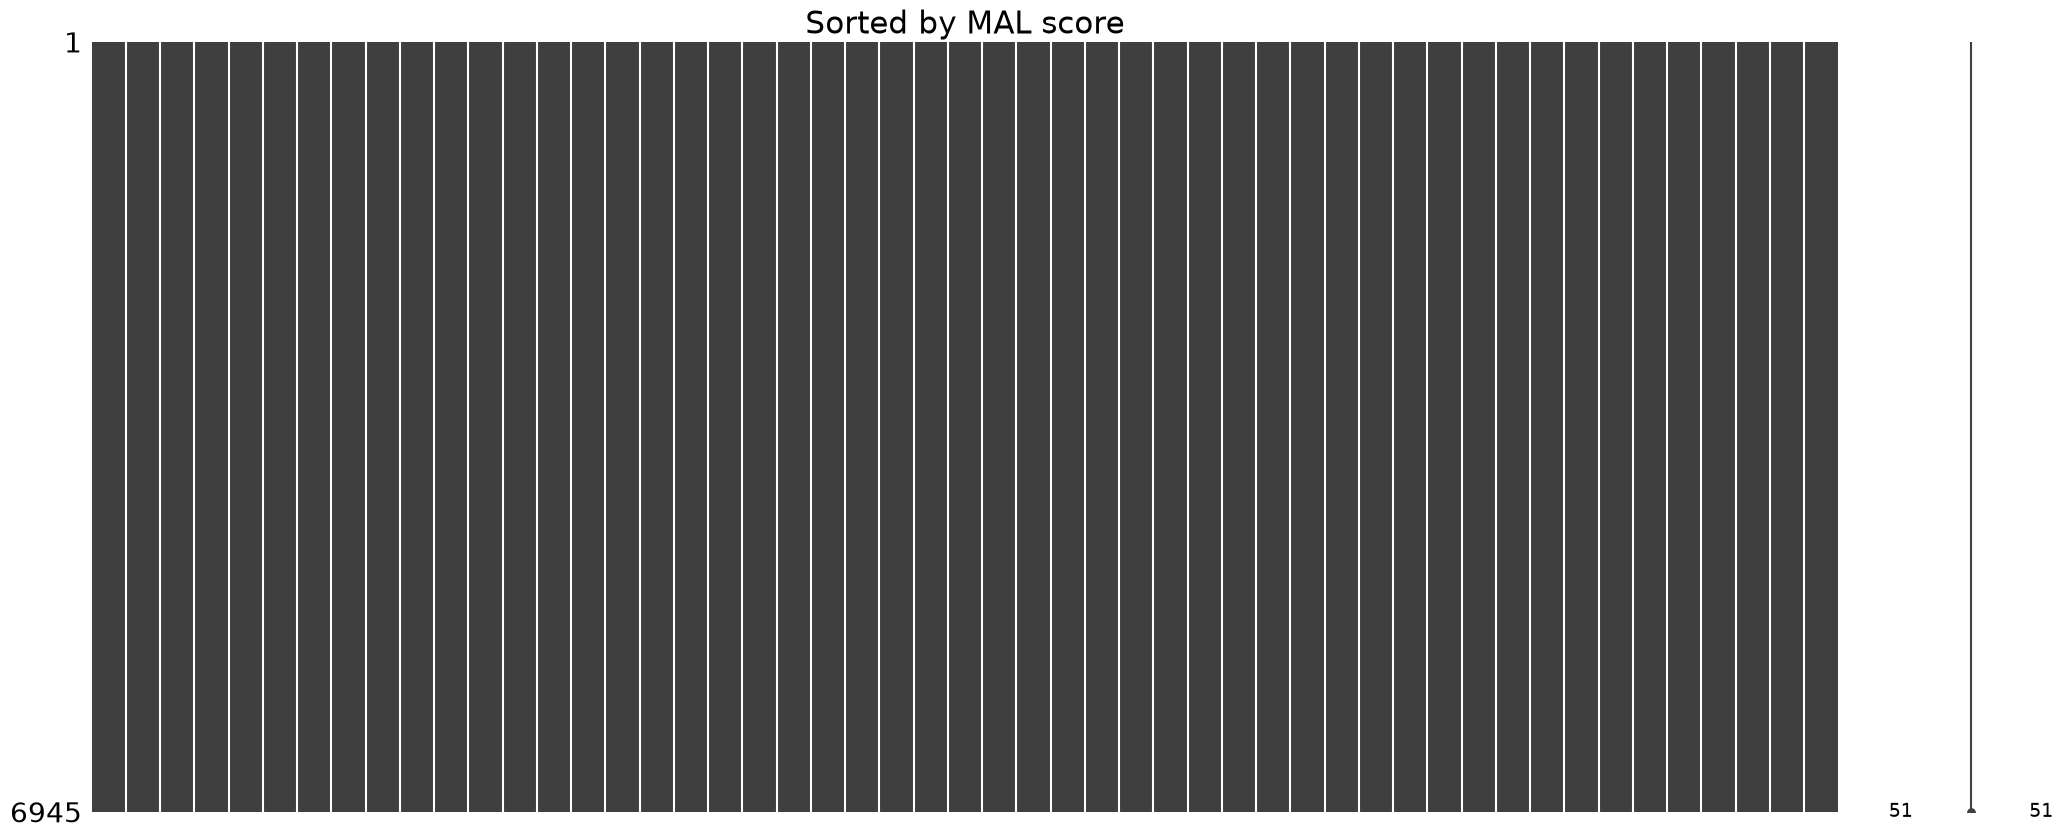

In [6]:
keep_cols = ['type', 'source', 'status','age_rating','season', 'year', 'episodes','duration_min', 'mal_score', 'anilist_score', 'score_gap_mal_anilist','studio_main', 'num_platforms', 'score_tier', 'popularity_tier', 'genres']
df = df[keep_cols]
# Drop rows with missing values
df = df.dropna(subset=keep_cols)
#Multi-hot Encoding the Genres; they are currently one object
from sklearn.preprocessing import MultiLabelBinarizer

genre_lists = df['genres'].str.split('|').apply(lambda lst: [g.strip() for g in lst])

mlb = MultiLabelBinarizer()
genre_encoded = pd.DataFrame(
    mlb.fit_transform(genre_lists),
    columns=mlb.classes_,
    index=df.index
)

# The dataset combined MAL Themes, MAL Genres, and Demographics into genres. Just keeping the Genres and Demographics
genres_to_keep = [
    'Action', 'Adventure', 'Avant Garde', 'Boys Love',
    'Comedy', 'Drama', 'Fantasy', 'Girls Love', 'Gourmet', 'Horror',
    'Mystery', 'Romance', 'Sci-Fi', 'Slice of Life', 'Sports',
    'Supernatural', 'Suspense', 'Josei', 'Kids', 'Seinen', 'Shoujo', 'Shounen'
]

# Filtering the encoded columns before merging into dataframe
genre_encoded = genre_encoded[[col for col in genre_encoded.columns if col in genres_to_keep]]

df = pd.concat([df, genre_encoded], axis=1)



#Getting rid of old genres column
del df['genres']


# One-hot encode type and source (currently strings)
df = pd.get_dummies(df, columns=['type', 'source'], drop_first=True)

#Encode popularity tier and score tier

score_map = {"Poor": 0, "Average": 1, "Good": 2, "Great": 3, "Masterpiece": 4}


df["score_tier_int"] = df["score_tier"].map(score_map)


#Now, we can remove the old score tier
del df['score_tier']


#Checking what the cleaned data looks like
df.to_csv('animecleaned3.csv', index=False)

#Checking to make sure there is no missing data
import missingno as mn
mn.matrix(df.sort_values(by=['mal_score']))
plt.title("Sorted by MAL score", fontsize=22)
plt.show()



With all the data cleaned, let's move on to creating the pipeline!

Agent Used: Microsoft Copilot GPT 6 - Luna

*Prompt:* "I am making a deep learning algorithm to calculate whether an anime is one of three options in the popularity_tier column (niche, top 5k, or top 1k). Create a pipeline for the cleaned dataset so that it can be provided to a model as a single input and modalities of data can be provided to the model as separate parallel inputs. Add this pipeline to a new cell below this one."

**LLM-Generated Code:**

When looking at this, I noticed the code decided to encode studio_main without grouping any of the values. The problem with this is that there are a wide variety of studios, including ones that are only mentioned once. The best way to handle this would be to start grouping smaller studios that have only made one or two shows to not have too many rows

Agent Used: Claude Sonnet 5.5 Medium

*Prompt:* There are a kajillion version of studio_main. Should I keep it in, and does the code above handle it properly, as it has not been onehotencoded?

**Response:**



Two quick corrections, then the recommendation.

The code does one-hot encode it. studio_main is in categorical_cols, so OneHotEncoder expands it into one column per unique studio, learned from the training set. So it “works,” but crudely. With thousands of studios, you’d get thousands of mostly-zero columns for about 6,700 training rows, and most studios would appear only once or twice. The network can’t learn anything reliable from a studio it has seen twice, and the extra width encourages overfitting. Also, any validation studio not seen in training is silently set to all zeros.

Should you keep it? Yes. Studio is probably one of your strongest signals (Toei, Madhouse, and Kyoto Animation titles tend to get more attention than obscure one-off studios), so dropping it would cost you real predictive power. The fix is to reduce the cardinality, not remove the feature.

Step 1: Clean the strings (before the split). Your data has inconsistent casing (I saw bones and MADHOUSE in the rows I looked at), so merge near-duplicates first:

python
df["studio_main"] = df["studio_main"].fillna("Unknown").astype(str).str.strip().str.lower()
print(df["studio_main"].value_counts().head(30))
print((df["studio_main"].value_counts() >= 20).sum(), "studios have 20+ titles")

Cleaning isn’t leakage, since it doesn’t use the labels or validation statistics.

Step 2, Option A (simplest): group rare studios in the encoder. One change to your existing line:

python
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)

Any category appearing fewer than 20 times in the training data is merged into a single “infrequent” column, and unseen validation studios are routed there too. This requires scikit-learn 1.1 or newer. Because the encoder is fit on training data only, there’s no leakage. Note that min_frequency applies to all of categorical_cols, which is fine for status, season, and age_rating, though it may merge a rare age rating.

Step 2, Option B (better for deep learning): use an embedding. Since you already have a parallel-inputs design, you can give studio its own branch. Map each studio to an integer ID, with 0 reserved for rare or unseen studios:

python
counts = train_df["studio_main"].value_counts()
keep = counts[counts >= 20].index
studio_to_id = {s: i + 1 for i, s in enumerate(keep)}   # 0 = rare/unknown

studio_train = train_df["studio_main"].map(studio_to_id).fillna(0).astype(np.int64).to_numpy()
studio_val = val_df["studio_main"].map(studio_to_id).fillna(0).astype(np.int64).to_numpy()

Then add a studio tensor (as torch.long) to your dataset’s modalities, remove studio_main from categorical_cols, and in the model feed it through nn.Embedding(len(keep) + 1, 8) before concatenating with the other branches. Note that the long tensor can’t be concatenated into the single float feature tensor, so this option only works with use_parallel_inputs = True unless you convert it to float or adjust the dataset. The embedding lets similar studios end up with similar vectors, which one-hot can’t do.

Which one? Start with Option A, since it’s a one-line change and gives a clean baseline. Try Option B if you want to show off what deep learning adds. Either way, pick the threshold (20 is a starting guess) by looking at the value_counts() output. And if you compare both, keep everything else fixed so the difference is attributable to the studio encoding.

In [10]:
%pip install torch torchvision

  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached filelock-4.2.6-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
    --------------------------------------- 3.1/126.7 MB 19.0 MB/s eta 0:00:07
   -- ------------------------------------- 7.9/126.7 MB 20.9 MB/s eta 0:00:06
   --- ------------------------------------ 12.6/126.7 MB 21.5 MB/s eta 0:00:06
   ----- ---------------------------------- 16.0/126.7 MB 20.6 MB/s eta 0:00:06
   ------ --------------------------------- 19.9/126.7 MB 19.9 MB/s eta 0:00:06
   ------- -------------------------------- 23.9/126.7 MB 20.1 MB/s eta 0:00:06
   -------- ------------------------------- 27.8/126.7 MB 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
#Let's onehotencode studio_main.
#First, merging near-dupes
df["studio_main"] = df["studio_main"].fillna("Unknown").astype(str).str.strip().str.lower()

#Now let's tweak the generated code to handle this

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Target indices: Niche=0, Top 5K=1, Top 1K=2.
label_map = {"niche": 0, "top 5k": 1, "top 1k": 2}
y_names = df["popularity_tier"].astype(str).str.strip().str.lower()
unknown = sorted(set(y_names) - set(label_map))
if unknown:
    raise ValueError(f"Unexpected popularity_tier values: {unknown}")
y = y_names.map(label_map).to_numpy(dtype=np.int64)

numeric_cols = ["year", "episodes", "duration_min", "mal_score", "anilist_score",
                "score_gap_mal_anilist", "num_platforms"]
categorical_cols = ["status", "age_rating", "season", "studio_main"]
binary_cols = [c for c in df if c.startswith(("type_", "source_"))]
genre_cols = ["Action", "Adventure", "Avant Garde", "Boys Love", "Comedy", "Drama",
              "Fantasy", "Girls Love", "Gourmet", "Horror", "Josei", "Kids",
              "Mystery", "Romance", "Sci-Fi", "Seinen", "Shoujo", "Shounen",
              "Slice of Life", "Sports", "Supernatural", "Suspense"]
required = numeric_cols + categorical_cols + binary_cols + genre_cols + ["popularity_tier"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing cleaned-data columns: {missing}")

# Split before fitting transforms to prevent validation-data leakage.
train_idx, val_idx = train_test_split(np.arange(len(df)), test_size=0.2,
                                      random_state=42, stratify=y)
train_df, val_df = df.iloc[train_idx], df.iloc[val_idx]

scaler = StandardScaler()
numeric_train = scaler.fit_transform(train_df[numeric_cols]).astype(np.float32)
numeric_val = scaler.transform(val_df[numeric_cols]).astype(np.float32)
## LINE EDIT: Changing the OneHotEncoder to handle infrequent categories instead of ignoring them

encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20)


category_train_encoded = encoder.fit_transform(train_df[categorical_cols]).toarray()
category_val_encoded = encoder.transform(val_df[categorical_cols]).toarray()
category_train = np.concatenate((category_train_encoded,
                                 train_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
category_val = np.concatenate((category_val_encoded,
                               val_df[binary_cols].to_numpy(dtype=np.float32)), axis=1)
genre_train = train_df[genre_cols].to_numpy(dtype=np.float32)
genre_val = val_df[genre_cols].to_numpy(dtype=np.float32)
y_train, y_val = y[train_idx], y[val_idx]

class AnimeDataset(Dataset):
    """Yield one concatenated tensor or separate tensors for each modality."""
    def __init__(self, numeric, categorical, genres, labels, input_mode="single"):
        if input_mode not in ("single", "parallel"):
            raise ValueError("input_mode must be 'single' or 'parallel'")
        self.input_mode = input_mode
        self.modalities = {
            "numeric": torch.tensor(numeric, dtype=torch.float32),
            "categorical": torch.tensor(categorical, dtype=torch.float32),
            "genres": torch.tensor(genres, dtype=torch.float32),
        }
        self.features = torch.cat(list(self.modalities.values()), dim=1)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        if self.input_mode == "parallel":
            return {name: values[index] for name, values in self.modalities.items()}, self.labels[index]
        return self.features[index], self.labels[index]

train_dataset_single = AnimeDataset(numeric_train, category_train, genre_train, y_train)
val_dataset_single = AnimeDataset(numeric_val, category_val, genre_val, y_val)
train_dataset_parallel = AnimeDataset(numeric_train, category_train, genre_train, y_train, "parallel")
val_dataset_parallel = AnimeDataset(numeric_val, category_val, genre_val, y_val, "parallel")

# True gives batches of modality tensors; False gives one concatenated feature tensor.
use_parallel_inputs = True
train_dataset = train_dataset_parallel if use_parallel_inputs else train_dataset_single
val_dataset = val_dataset_parallel if use_parallel_inputs else val_dataset_single
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

print("Class mapping:", label_map)
print("Train/validation rows:", len(train_dataset), len(val_dataset))
print("Single input width:", train_dataset_single.features.shape[1])
print("Parallel modality widths:", {name: x.shape[1] for name, x in train_dataset_parallel.modalities.items()})


Class mapping: {'niche': 0, 'top 5k': 1, 'top 1k': 2}
Train/validation rows: 5556 1389
Single input width: 122
Parallel modality widths: {'numeric': 7, 'categorical': 93, 'genres': 22}


## Model Construction

*You may use an LLM to help generate model code, assuming you verify all generated code and explain architectural decisions in your own words.*

 - *Single modality Input: Construct a single input feedforward neural network using PyTorch or Keras for your dataset. The network should contain*
    - input layer
    - at least two hidden layers (likely more are needed)
    - output layer
    - nonlinear activation functions
- *Multiple Modality Input: Construct a similar model that takes multiple inputs as separate modalities. These modalities should be processed separately (i.e., with a hidden layer for that modality or an embedding layer for each modality) before the representations are combined and processed for the remainder of the network. This is similar to we processed each modality of categorical data in class.*
- *Optional: Instead of single- and multi-modality, teams can also investigate the multi- versus crossed-models (i.e., wide and deep)*
- *Teams must investigate three hyper-parameters with two unique values per hyper-parameter (resulting in eight total models trained in a grid search):*
    - single modality input versus multi-modal input
    - number of hidden layers (investigate using two hidden layers and more than two hidden layers)
    - choose one: {type of activation functions, choose two}  OR {the amount of dropout used, choose two value}

For this, we decided to focus on single modality vs multiple modality inputs as well as varying the type of activation functions. For the activation functions, we picked ReLU, as it is the common default, being unbounded, piecewise linear, and outputs exact zeroes. Tanh is the opposite, being smooth, bounded, and saturates at the extremes. Therefore, its best to compare two completely opposed activation functions rather than ones that are super similar. 

### Single Modality Input

Agent Used: Microsoft Copilot GPT 6 - Luna

*Prompt:* Using the Training Pipeline earlier in the code, create a single modality and multiple modality input model for the dataset, using ReLU as its activation function of choice. Make sure the code is fully commented explaining what each part of the code does. They should have two hidden layers.

**LLM Output:** (Comment dividers added by hand)

In [19]:
# Import PyTorch's neural-network building blocks for the two classifiers.
import torch.nn as nn

# Define the single-input model that consumes the pipeline's concatenated features.
class SingleInputAnimeModel(nn.Module): ##SingleInput - 2 layers, ReLU activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.ReLU()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.ReLU()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)


# Define a multi-input model that separately learns a representation for each modality.
class MultiModalAnimeModel(nn.Module): #MultimodalInput - 2 layers, ReLU activations
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        # Initialize PyTorch's module bookkeeping before adding child layers.
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Give each modality its own first hidden layer and ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.ReLU(),
            )
            for name in self.modality_names
        })

        # Concatenate the three branch outputs, then apply the second hidden layer and ReLU.
        self.fusion_layer = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_relu = nn.ReLU()

        # Convert the fused representation to one logit for each of the three classes.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process numeric, categorical, and genre inputs independently through their branches.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Join the modality representations along the feature dimension for fusion.
        combined = torch.cat(branch_outputs, dim=1)

        # Apply the fused second hidden layer and its ReLU activation.
        hidden = self.fusion_relu(self.fusion_layer(combined))

        # Return class logits for use with a multiclass loss such as CrossEntropyLoss.
        return self.output_layer(hidden)


## NOTE: COMMENTED THE BELOW OUT; WILL BE MODIFYING IT FOR ALL OF THE MODELS WHEN THEY'RE ALL MADE

# # Read input widths directly from the datasets created by the training pipeline.
# num_classes = len(label_map)
# single_input_size = train_dataset_single.features.shape[1]
# modality_sizes = {
#     name: tensor.shape[1]
#     for name, tensor in train_dataset_parallel.modalities.items()
# }

# # Instantiate both models with two hidden layers and ReLU activations.
# single_input_model = SingleInputAnimeModel(single_input_size, num_classes=num_classes)
# multi_modal_model = MultiModalAnimeModel(modality_sizes, num_classes=num_classes)

# # Run a small shape check using real batches; this confirms both models produce 3 logits per row.
# single_features, _ = next(iter(DataLoader(train_dataset_single, batch_size=4)))
# parallel_features, _ = next(iter(DataLoader(train_dataset_parallel, batch_size=4)))
# single_logits = single_input_model(single_features)
# multi_modal_logits = multi_modal_model(parallel_features)
# print("Single-input logits shape:", tuple(single_logits.shape))
# print("Multi-modal logits shape:", tuple(multi_modal_logits.shape))

In [20]:
#Tweaking it by hand for the rest
class SingleInputAnimeModel2Tanh(nn.Module): ##SingleInput - 2 layers, Tanh activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply Tanh.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.tanh_1 = nn.Tanh()

        # Transform the first representation through the second hidden layer and Tanh.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.tanh_2 = nn.Tanh()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.tanh_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.tanh_2(self.hidden_layer_2(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)

class SingleInputAnimeModel4ReLU(nn.Module): ##SingleInput - 4 layers, ReLU activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.ReLU()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.ReLU()

        self.hidden_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.act_3 = nn.ReLU()

        self.hidden_layer_4 = nn.Linear(hidden_size, hidden_size)
        self.act_4 = nn.ReLU()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Apply the third fully connected hidden layer and its nonlinear activation.
        hidden = self.act_3(self.hidden_layer_3(hidden))

        # Apply the fourth fully connected hidden layer and its nonlinear activation.
        hidden = self.act_4(self.hidden_layer_4(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)


class SingleInputAnimeModel4Tanh(nn.Module): ##SingleInput - 4 layers, Tanh activations
    def __init__(self, input_size, hidden_size=128, num_classes=3):
        # Initialize the PyTorch module so its layers and parameters are registered.
        super().__init__()

        # Map the full feature vector to the first hidden representation, then apply ReLU.
        self.hidden_layer_1 = nn.Linear(input_size, hidden_size)
        self.relu_1 = nn.Tanh()

        # Transform the first representation through the second hidden layer and ReLU.
        self.hidden_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.relu_2 = nn.Tanh()

        self.hidden_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.act_3 = nn.Tanh()

        self.hidden_layer_4 = nn.Linear(hidden_size, hidden_size)
        self.act_4 = nn.Tanh()

        # Produce one unnormalized score (logit) for each popularity class.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, features):
        # Apply the first fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_1(self.hidden_layer_1(features))

        # Apply the second fully connected hidden layer and its nonlinear activation.
        hidden = self.relu_2(self.hidden_layer_2(hidden))

        # Apply the third fully connected hidden layer and its nonlinear activation.
        hidden = self.act_3(self.hidden_layer_3(hidden))

        # Apply the fourth fully connected hidden layer and its nonlinear activation.
        hidden = self.act_4(self.hidden_layer_4(hidden))

        # Return class logits; CrossEntropyLoss applies the appropriate normalization.
        return self.output_layer(hidden)

class MultiModalAnimeModel2Tanh(nn.Module): #MultimodalInput - 2 layers, Tanh activations
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        # Initialize PyTorch's module bookkeeping before adding child layers.
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Give each modality its own first hidden layer and ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.Tanh(),
            )
            for name in self.modality_names
        })

        # Concatenate the three branch outputs, then apply the second hidden layer and ReLU.
        self.fusion_layer = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_tanh = nn.Tanh()

        # Convert the fused representation to one logit for each of the three classes.
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process numeric, categorical, and genre inputs independently through their branches.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Join the modality representations along the feature dimension for fusion.
        combined = torch.cat(branch_outputs, dim=1)

        # Apply the fused second hidden layer and its ReLU activation.
        hidden = self.fusion_tanh(self.fusion_layer(combined))

        # Return class logits for use with a multiclass loss such as CrossEntropyLoss.
        return self.output_layer(hidden)

### Multiple Modality Input

Construct a similar model that takes multiple inputs as separate modalities. These modalities should be processed separately (i.e., with a hidden layer for that modality or an embedding layer for each modality) before the representations are combined and processed for the remainder of the network. This is similar to we processed each modality of categorical data in class.

I was a bit confused on how to write multiple layers in multimodal models, so I asked Claude how to do it.

Agent Used: Claude Sonnet 5.5 Medium

*Prompt*: "How about tweaking this to use relu and 4 layers?" (Pasted multimoldal code using Tanh)

**LLM Output:**

In [24]:
class MultiModalAnimeModel4ReLU(nn.Module):  # MultimodalInput - 4 hidden layers, ReLU
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Hidden layer 1: each modality gets its own Linear layer + ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.ReLU(),
            )
            for name in self.modality_names
        })

        # Hidden layer 2: fuse the concatenated branch outputs.
        self.fusion_layer_1 = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_act_1 = nn.ReLU()

        # Hidden layer 3.
        self.fusion_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_2 = nn.ReLU()

        # Hidden layer 4.
        self.fusion_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_3 = nn.ReLU()

        # Output layer: one logit per class (no activation; CrossEntropyLoss handles softmax).
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process each modality independently through its own branch.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Concatenate the branch representations along the feature dimension.
        combined = torch.cat(branch_outputs, dim=1)

        # Pass the fused representation through the three fusion layers.
        hidden = self.fusion_act_1(self.fusion_layer_1(combined))
        hidden = self.fusion_act_2(self.fusion_layer_2(hidden))
        hidden = self.fusion_act_3(self.fusion_layer_3(hidden))

        # Return class logits.
        return self.output_layer(hidden)

In [22]:
##Tweaked the code above for Tanh

class MultiModalAnimeModel4Tanh(nn.Module):  # MultimodalInput - 4 hidden layers, Tanh
    def __init__(self, modality_sizes, branch_size=32, hidden_size=64, num_classes=3):
        super().__init__()

        # Keep a stable order so each input tensor is matched to its modality branch.
        self.modality_names = ("numeric", "categorical", "genres")

        # Hidden layer 1: each modality gets its own Linear layer + ReLU before fusion.
        self.modality_branches = nn.ModuleDict({
            name: nn.Sequential(
                nn.Linear(modality_sizes[name], branch_size),
                nn.Tanh(),
            )
            for name in self.modality_names
        })

        # Hidden layer 2: fuse the concatenated branch outputs.
        self.fusion_layer_1 = nn.Linear(branch_size * len(self.modality_names), hidden_size)
        self.fusion_act_1 = nn.Tanh()

        # Hidden layer 3.
        self.fusion_layer_2 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_2 = nn.Tanh()

        # Hidden layer 4.
        self.fusion_layer_3 = nn.Linear(hidden_size, hidden_size)
        self.fusion_act_3 = nn.Tanh()

        # Output layer: one logit per class (no activation; CrossEntropyLoss handles softmax).
        self.output_layer = nn.Linear(hidden_size, num_classes)

    def forward(self, modalities):
        # Process each modality independently through its own branch.
        branch_outputs = [
            self.modality_branches[name](modalities[name])
            for name in self.modality_names
        ]

        # Concatenate the branch representations along the feature dimension.
        combined = torch.cat(branch_outputs, dim=1)

        # Pass the fused representation through the three fusion layers.
        hidden = self.fusion_act_1(self.fusion_layer_1(combined))
        hidden = self.fusion_act_2(self.fusion_layer_2(hidden))
        hidden = self.fusion_act_3(self.fusion_layer_3(hidden))

        # Return class logits.
        return self.output_layer(hidden)

In [ ]:
# Read input widths directly from the datasets created by the training pipeline.
num_classes = len(label_map)
single_input_size = train_dataset_single.features.shape[1]
modality_sizes = {
    name: tensor.shape[1]
    for name, tensor in train_dataset_parallel.modalities.items()
}

# Instantiate both models with two hidden layers and ReLU activations.
single_input_model_2_ReLU = SingleInputAnimeModel(single_input_size, num_classes=num_classes)
single_input_model_2_Tanh = SingleInputAnimeModel2Tanh(single_input_size, num_classes=num_classes)
single_input_model_4_ReLU = SingleInputAnimeModel4ReLU(single_input_size, num_classes=num_classes)
single_input_model_4_Tanh = SingleInputAnimeModel4Tanh(single_input_size, num_classes=num_classes)
multi_modal_model_2_ReLU = MultiModalAnimeModel(modality_sizes, num_classes=num_classes)
multi_modal_model_2_Tanh = MultiModalAnimeModel2Tanh(modality_sizes, num_classes=num_classes)
multi_modal_model_4_ReLU = MultiModalAnimeModel4ReLU(modality_sizes, num_classes=num_classes)
multi_modal_model_4_Tanh = MultiModalAnimeModel4Tanh(modality_sizes, num_classes=num_classes)

# Run a small shape check using real batches; this confirms both models produce 3 logits per row.
single_features, _ = next(iter(DataLoader(train_dataset_single, batch_size=4)))
parallel_features, _ = next(iter(DataLoader(train_dataset_parallel, batch_size=4)))
single_logits_2_reLU = single_input_model_2_ReLU(single_features)
single_logits_2_Tanh = single_input_model_2_Tanh(single_features)
single_logits_4_reLU = single_input_model_4_ReLU(single_features)
single_logits_4_Tanh = single_input_model_4_Tanh(single_features)
multi_modal_logits_2_reLU = multi_modal_model_2_ReLU(parallel_features)
multi_modal_logits_2_Tanh = multi_modal_model_2_Tanh(parallel_features)
multi_modal_logits_4_reLU = multi_modal_model_4_ReLU(parallel_features)
multi_modal_logits_4_Tanh = multi_modal_model_4_ReLU(parallel_features)
print("Single-input, 2 layer, ReLU logits shape:", tuple(single_logits_2_reLU.shape))
print("Single-input, 2 layer, Tanh logits shape:", tuple(single_logits_2_Tanh.shape))
print("Single-input, 4 layer, ReLU logits shape:", tuple(single_logits_4_reLU.shape))
print("Single-input, 4 layer, Tanh logits shape:", tuple(single_logits_4_Tanh.shape))
print("Multi-modal, 2 layer, ReLU logits shape:", tuple(multi_modal_logits_2_reLU.shape))
print("Multi-modal, 2 layer, Tanh logits shape:", tuple(multi_modal_logits_2_Tanh.shape))
print("Multi-modal, 4 layer, ReLU logits shape:", tuple(multi_modal_logits_4_reLU.shape))
print("Multi-modal, 4 layer, Tanh logits shape:", tuple(multi_modal_logits_4_Tanh.shape))

Single-input, 2 layer, ReLU logits shape: (4, 3)
Single-input, 2 layer, Tanh logits shape: (4, 3)
Single-input, 4 layer, ReLU logits shape: (4, 3)
Single-input, 4 layer, Tanh logits shape: (4, 3)
Multi-modal, 2 layer, ReLU logits shape: (4, 3)
Multi-modal, 2 layer, Tanh logits shape: (4, 3)
Multi-modal, 4 layer, ReLU logits shape: (4, 3)
Multi-modal, 4 layer, Tanh logits shape: (4, 3)


## Training and Optimization
You will train the eight model variations to convergence.

Before training all eight models, you should investigate hyperparameters of training for one of the models. For this one model, teams should investigate at least three training parameters: learning rate, optimizer, and batch size. LLMs may be used to generate experimentation code. Once an appropriate set of training parameters is selected from this example model, teams should train all eight models to convergence. Plots of the loss function versus epoch for each of the eight models should be shown. These loss curves for training and validation should be used to verify convergence.

The model we have chosen to investigate will be MultiModalAnimeModel4Tanh, the multi-modal model with four layers and the Tanh logits shape. 

*Prompt:* Before training my eight model variations to convergence, I want to investigate hyperparameters of training for the training model, MultiModalAnimeModel4Tanh. I want to investigate three training parameters: learning rate, optimizer, and batch size. Please generate some experimentation code. Make sure the code is fully commented explaining what each part of the code does.

Agent used: Claude Sonnet 5.5

**LLM Output:** I wrote the experiment code to hyperparam_experiment.py, fully commented, ready to paste into a cell after your model-construction cells. I haven’t run it, since the data and kernel are on your machine.

What it does
- It runs a full grid over 4 optimizers (SGD with momentum, Adam, AdamW, RMSprop), 3 learning rates (1e-4, 1e-3, 1e-2) and 3 batch sizes (32, 64, 128). That is 36 runs on about 5.5k rows, so it should finish in a few minutes.
- Every run builds a fresh MultiModalAnimeModel4Tanh and uses the same seed, so differences come only from the hyperparameters.
- Each run trains for up to 60 epochs and stops early if validation loss hasn’t improved for 8 epochs. It also stops if the loss goes NaN, which can happen at lr=1e-2.
- Each run is scored on its best validation loss, with accuracy and macro-F1 recorded at that epoch. I included macro-F1 because Niche likely dominates your classes, so accuracy alone could look good while the model ignores Top 1K.
- It prints the top 10 configurations. It also prints the best loss for each optimizer, learning rate and batch size, with the spread, so you can say which parameter mattered most.
- It plots a heatmap of learning rate against batch size for each optimizer, and the train/validation loss curves for the three best configurations.
- It stores the winner in BEST_OPTIMIZER, BEST_LR and BEST_BATCH_SIZE, so you can reuse them when you train the eight final models.

Things to check
- Use the loss-curve plot to confirm the winner has actually converged. If its best epoch is right at MAX_EPOCHS, raise that limit.
- Selection uses your validation set, so the reported validation numbers will be a little optimistic. If you have a held-out test set, report final metrics on that.
- If the assignment wants fewer runs, you can trim learning_rates, batch_sizes or optimizer_factories at the top of the file.

In [ ]:
# Experimentation Code 
# ============================================================
# Hyperparameter investigation for MultiModalAnimeModel4Tanh
# Parameters studied: learning rate, optimizer, batch size
#
# Paste into a notebook cell AFTER the model-construction cells.
# It relies on these variables already defined in the notebook:
#   train_dataset_parallel, val_dataset_parallel, modality_sizes,
#   num_classes, MultiModalAnimeModel4Tanh
# ============================================================

import copy
import itertools
import random
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. Setup: device, reproducibility, and the search space
# ------------------------------------------------------------

# Use a GPU if one is available; otherwise fall back to the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42            # same seed for every run so differences come from the hyperparameters
MAX_EPOCHS = 60      # upper limit on training length for each experiment
PATIENCE = 8         # stop a run if validation loss hasn't improved for this many epochs

# The three hyperparameters under investigation and the values to try.
learning_rates = [1e-4, 1e-3, 1e-2]
batch_sizes = [32, 64, 128]

# Each optimizer is stored as a function that builds it from (parameters, learning rate).
# SGD gets momentum, because plain SGD is usually far too slow on a small network.
optimizer_factories = {
    "SGD+momentum": lambda params, lr: torch.optim.SGD(params, lr=lr, momentum=0.9),
    "Adam":         lambda params, lr: torch.optim.Adam(params, lr=lr),
    "AdamW":        lambda params, lr: torch.optim.AdamW(params, lr=lr),
    "RMSprop":      lambda params, lr: torch.optim.RMSprop(params, lr=lr),
}


def set_seed(seed):
    """Seed Python, NumPy and PyTorch so each experiment starts from identical conditions."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# 2. Helpers: move a batch to the device, run one epoch, evaluate
# ------------------------------------------------------------

def to_device(inputs):
    """The multimodal dataset yields a dict of tensors; move every tensor in it to the device."""
    return {name: tensor.to(device) for name, tensor in inputs.items()}


def train_one_epoch(model, loader, loss_fn, optimizer):
    """One full pass over the training data with backprop. Returns the mean training loss."""
    model.train()                       # training mode (enables dropout/batchnorm if present)
    total_loss, total_samples = 0.0, 0
    for inputs, labels in loader:
        inputs, labels = to_device(inputs), labels.to(device)
        optimizer.zero_grad()           # clear gradients left over from the previous batch
        logits = model(inputs)          # forward pass
        loss = loss_fn(logits, labels)  # compare predictions with the true popularity tier
        loss.backward()                 # backpropagate
        optimizer.step()                # update weights
        total_loss += loss.item() * labels.size(0)   # weight by batch size (last batch may be smaller)
        total_samples += labels.size(0)
    return total_loss / total_samples


@torch.no_grad()                        # no gradients needed when only evaluating
def evaluate(model, loader, loss_fn):
    """Forward pass only. Returns validation loss, accuracy and macro-F1."""
    model.eval()                        # evaluation mode
    total_loss, total_samples = 0.0, 0
    all_preds, all_labels = [], []
    for inputs, labels in loader:
        inputs, labels = to_device(inputs), labels.to(device)
        logits = model(inputs)
        total_loss += loss_fn(logits, labels).item() * labels.size(0)
        total_samples += labels.size(0)
        all_preds.append(logits.argmax(dim=1).cpu())    # predicted class = largest logit
        all_labels.append(labels.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    accuracy = (preds == labels).mean()
    # Macro-F1 averages over classes equally, so it isn't dominated by the large "Niche" class.
    macro_f1 = f1_score(labels, preds, average="macro")
    return total_loss / total_samples, accuracy, macro_f1


# ------------------------------------------------------------
# 3. One experiment = one (optimizer, learning rate, batch size) combination
# ------------------------------------------------------------

def run_experiment(opt_name, lr, batch_size):
    """Train a fresh model with the given settings; return a summary dict and the loss history."""
    set_seed(SEED)                      # identical weight init and shuffling order each time

    # Training data is shuffled each epoch; validation data never needs shuffling.
    train_loader = DataLoader(train_dataset_parallel, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset_parallel, batch_size=256, shuffle=False)

    # Fresh model every run, so earlier experiments cannot leak into later ones.
    model = MultiModalAnimeModel4Tanh(modality_sizes, num_classes=num_classes).to(device)
    loss_fn = nn.CrossEntropyLoss()     # standard multiclass loss (takes raw logits)
    optimizer = optimizer_factories[opt_name](model.parameters(), lr)

    history = {"train_loss": [], "val_loss": []}
    best_val_loss, best_epoch, epochs_without_improvement = float("inf"), 0, 0
    best_metrics = (np.nan, np.nan)     # (accuracy, macro-F1) at the best epoch

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc, val_f1 = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Track the best validation loss; this is the "converged" point we compare on.
        if val_loss < best_val_loss - 1e-4:
            best_val_loss, best_epoch = val_loss, epoch
            best_metrics = (val_acc, val_f1)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Early stopping: validation loss has stopped improving (convergence or overfitting).
        if epochs_without_improvement >= PATIENCE:
            break

        # Diverged (NaN loss) - no point continuing, which can happen with lr=1e-2.
        if not np.isfinite(train_loss):
            break

    summary = {
        "optimizer": opt_name,
        "lr": lr,
        "batch_size": batch_size,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "val_accuracy": best_metrics[0],
        "val_macro_f1": best_metrics[1],
        "final_train_loss": history["train_loss"][-1],
        "epochs_run": len(history["train_loss"]),
    }
    return summary, history


# ------------------------------------------------------------
# 4. Run the full grid: 4 optimizers x 3 learning rates x 3 batch sizes = 36 runs
# ------------------------------------------------------------

results, histories = [], {}
start = time.time()
for opt_name, lr, bs in itertools.product(optimizer_factories, learning_rates, batch_sizes):
    summary, history = run_experiment(opt_name, lr, bs)
    results.append(summary)
    histories[(opt_name, lr, bs)] = history
    print(f"{opt_name:13s} lr={lr:<7g} bs={bs:<4d} "
          f"best val loss={summary['best_val_loss']:.4f} (epoch {summary['best_epoch']:2d}) "
          f"acc={summary['val_accuracy']:.3f} macroF1={summary['val_macro_f1']:.3f}")
print(f"Grid finished in {time.time() - start:.0f}s")

results_df = pd.DataFrame(results).sort_values("best_val_loss").reset_index(drop=True)
print("\nTop 10 configurations by validation loss:")
print(results_df.head(10).to_string())

# ------------------------------------------------------------
# 5. How much does each hyperparameter matter on its own?
#    For each value of a hyperparameter, take the best result across all
#    settings of the other two. A bigger spread = a more influential parameter.
# ------------------------------------------------------------

for param in ["optimizer", "lr", "batch_size"]:
    best_per_value = results_df.groupby(param)["best_val_loss"].min()
    print(f"\nBest validation loss for each {param}:")
    print(best_per_value.to_string())
    print(f"  spread (max - min): {best_per_value.max() - best_per_value.min():.4f}")

# ------------------------------------------------------------
# 6. Visualise the results
# ------------------------------------------------------------

# 6a. Heatmaps of best validation loss (learning rate vs batch size), one per optimizer.
fig, axes = plt.subplots(1, len(optimizer_factories), figsize=(5 * len(optimizer_factories), 4),
                         sharey=True)
vmin, vmax = results_df["best_val_loss"].min(), results_df["best_val_loss"].quantile(0.9)
for ax, opt_name in zip(axes, optimizer_factories):
    grid = (results_df[results_df.optimizer == opt_name]
            .pivot(index="batch_size", columns="lr", values="best_val_loss"))
    im = ax.imshow(grid.values, cmap="viridis_r", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(grid.columns)))
    ax.set_xticklabels([f"{c:g}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels(grid.index)
    ax.set_title(opt_name)
    ax.set_xlabel("Learning rate")
    for i in range(grid.shape[0]):          # print the number in each cell
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center",
                    color="white", fontsize=9)
axes[0].set_ylabel("Batch size")
fig.colorbar(im, ax=axes, label="Best validation loss (lower is better)")
plt.suptitle("MultiModalAnimeModel4Tanh: hyperparameter grid")
plt.show()

# 6b. Train/validation loss curves for the three best configurations,
#     to check that they have actually converged and aren't badly overfitting.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (_, row) in zip(axes, results_df.head(3).iterrows()):
    key = (row.optimizer, row.lr, int(row.batch_size))
    ax.plot(histories[key]["train_loss"], label="Train")
    ax.plot(histories[key]["val_loss"], label="Validation")
    ax.axvline(row.best_epoch - 1, color="gray", linestyle="--", label="Best epoch")
    ax.set_title(f"{row.optimizer}, lr={row.lr:g}, bs={int(row.batch_size)}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save the winning settings so the eight final models can reuse them
# ------------------------------------------------------------

best = results_df.iloc[0]
BEST_OPTIMIZER, BEST_LR, BEST_BATCH_SIZE = best.optimizer, best.lr, int(best.batch_size)
print(f"\nSelected settings -> optimizer: {BEST_OPTIMIZER}, lr: {BEST_LR:g}, "
      f"batch size: {BEST_BATCH_SIZE}")

We will now train all eight models to convergence

*Prompt:* Please give me code that will train single_input_model_2_ReLU to convergence. Will the code to train all eight models follow a similar format as each other? Make sure the code is fully commented explaining what each part of the code does.

Agent used: Microsoft Copilot GPT 6 - Luna

**LLM Output:** Yes, the training code for all eight models can follow the same format: use the same helper, loss, optimizer settings, stopping rule, and plotting. The main difference is the inputs: single-input models use train_dataset_single and val_dataset_single; multimodal models use the corresponding *_parallel datasets. I checked the code for Python syntax errors; I have not run the training itself.

In [44]:
import math
from copy import deepcopy

# Use an available GPU for faster training, or use the CPU if no GPU is available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _move_inputs_to_device(inputs):
    """Move either concatenated features or a multimodal dictionary to the device."""
    if isinstance(inputs, dict):
        return {name: tensor.to(device) for name, tensor in inputs.items()}
    return inputs.to(device)


def _run_epoch(model, loader, loss_function, optimizer=None):
    """Run one training or validation epoch and return its sample-weighted loss."""
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    total_samples = 0

    for inputs, labels in loader:
        inputs = _move_inputs_to_device(inputs)
        labels = labels.to(device)

        # Track gradients and update weights only during the training phase.
        with torch.set_grad_enabled(is_training):
            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)
            loss = loss_function(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        # Stop with an explicit error if training becomes numerically unstable.
        loss_value = loss.item()
        if not math.isfinite(loss_value):
            raise RuntimeError("Loss became non-finite; try a smaller learning rate.")

        # Weight batch losses by their sample counts so a short last batch is handled correctly.
        batch_samples = labels.size(0)
        total_loss += loss_value * batch_samples
        total_samples += batch_samples

    # Return the average loss per example for this complete pass over the dataset.
    return total_loss / total_samples


def fit_to_convergence(model, train_dataset, val_dataset, model_name):
    """Train with the selected hyperparameters, early stopping, and best-weight restoration."""
    # Shuffle training examples each epoch; keep validation ordering fixed.
    train_loader = DataLoader(
        train_dataset, batch_size=BEST_BATCH_SIZE, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BEST_BATCH_SIZE, shuffle=False
    )

    # Move the model to the same device as its batches and create the chosen loss and optimizer.
    model = model.to(device)
    loss_function = nn.CrossEntropyLoss()
    optimizer = optimizer_factories[BEST_OPTIMIZER](model.parameters(), BEST_LR)

    # Limit the maximum runtime and stop when validation loss has plateaued.
    max_epochs = 200
    patience = 12
    min_delta = 1e-4

    # Store separate training and validation losses to plot and inspect convergence.
    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    best_state = None

    # Train until validation loss stops improving or the safety epoch limit is reached.
    for epoch in range(1, max_epochs + 1):
        train_loss = _run_epoch(model, train_loader, loss_function, optimizer)
        val_loss = _run_epoch(model, val_loader, loss_function)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Keep a copy of the weights from the epoch with the lowest validation loss.
        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        # Print progress so decreasing or stalled losses are visible while training.
        print(
            f"{model_name} | epoch {epoch:03d} | "
            f"train loss {train_loss:.4f} | validation loss {val_loss:.4f}"
        )

        # Stop once the validation loss has failed to improve for the patience window.
        if epochs_without_improvement >= patience:
            print(f"Early stopping after {epoch} epochs.")
            break
    else:
        # The loop's else block runs only when max_epochs is reached without early stopping.
        print(f"Reached max_epochs={max_epochs}; consider increasing it if loss is still falling.")

    # Restore the best validation checkpoint rather than returning later, possibly overfit weights.
    if best_state is None:
        raise RuntimeError("Training ended without a valid model checkpoint.")
    model.load_state_dict(best_state)

    # Report the checkpoint selected by validation loss.
    print(
        f"{model_name} best checkpoint: epoch {best_epoch}, "
        f"validation loss {best_val_loss:.4f}; "
        f"optimizer={BEST_OPTIMIZER}, learning rate={BEST_LR:g}, "
        f"batch size={BEST_BATCH_SIZE}"
    )

    # Plot both loss curves so convergence and possible overfitting can be assessed.
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["train_loss"], label="Training loss")
    plt.plot(epochs, history["val_loss"], label="Validation loss")
    plt.axvline(best_epoch, color="gray", linestyle="--", label="Best validation epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{model_name}: training and validation loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Return the trained model and its loss history for later evaluation or comparison.
    return model, history

The following cells train each of the eight models

single_input_model_2_ReLU | epoch 001 | train loss 0.3091 | validation loss 0.4884
single_input_model_2_ReLU | epoch 002 | train loss 0.3088 | validation loss 0.4952
single_input_model_2_ReLU | epoch 003 | train loss 0.2940 | validation loss 0.5047
single_input_model_2_ReLU | epoch 004 | train loss 0.2928 | validation loss 0.5205
single_input_model_2_ReLU | epoch 005 | train loss 0.2815 | validation loss 0.5231
single_input_model_2_ReLU | epoch 006 | train loss 0.2720 | validation loss 0.6109
single_input_model_2_ReLU | epoch 007 | train loss 0.2599 | validation loss 0.5775
single_input_model_2_ReLU | epoch 008 | train loss 0.2692 | validation loss 0.5302
single_input_model_2_ReLU | epoch 009 | train loss 0.2472 | validation loss 0.5456
single_input_model_2_ReLU | epoch 010 | train loss 0.2547 | validation loss 0.5725
single_input_model_2_ReLU | epoch 011 | train loss 0.2324 | validation loss 0.6128
single_input_model_2_ReLU | epoch 012 | train loss 0.2475 | validation loss 0.5731
sing

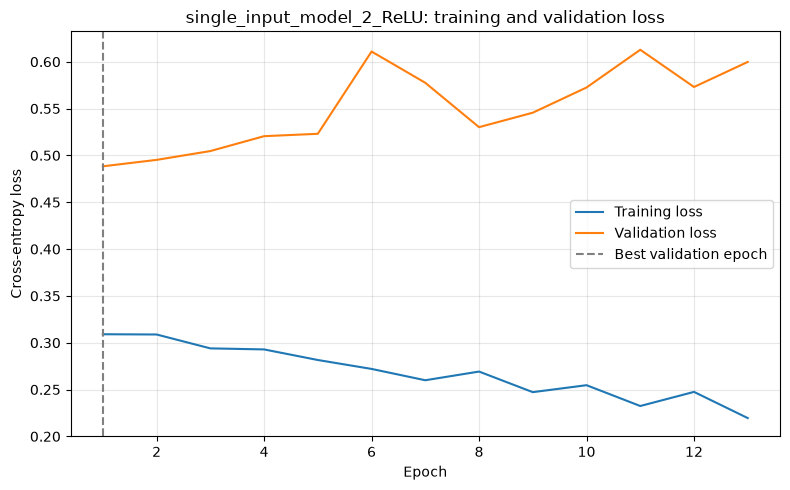

In [45]:
# Train single_input_model_2_ReLU to convergence
single_input_model_2_ReLU, single_input_model_2_ReLU_history = fit_to_convergence(
    single_input_model_2_ReLU,
    train_dataset_single,
    val_dataset_single,
    "single_input_model_2_ReLU",
)

single_input_model_2_Tanh | epoch 001 | train loss 0.6673 | validation loss 0.5859
single_input_model_2_Tanh | epoch 002 | train loss 0.5467 | validation loss 0.5598
single_input_model_2_Tanh | epoch 003 | train loss 0.5314 | validation loss 0.5559
single_input_model_2_Tanh | epoch 004 | train loss 0.5235 | validation loss 0.5671
single_input_model_2_Tanh | epoch 005 | train loss 0.5209 | validation loss 0.5451
single_input_model_2_Tanh | epoch 006 | train loss 0.5149 | validation loss 0.5500
single_input_model_2_Tanh | epoch 007 | train loss 0.5100 | validation loss 0.5774
single_input_model_2_Tanh | epoch 008 | train loss 0.5015 | validation loss 0.5412
single_input_model_2_Tanh | epoch 009 | train loss 0.4991 | validation loss 0.5357
single_input_model_2_Tanh | epoch 010 | train loss 0.4976 | validation loss 0.5484
single_input_model_2_Tanh | epoch 011 | train loss 0.4879 | validation loss 0.5429
single_input_model_2_Tanh | epoch 012 | train loss 0.4797 | validation loss 0.5166
sing

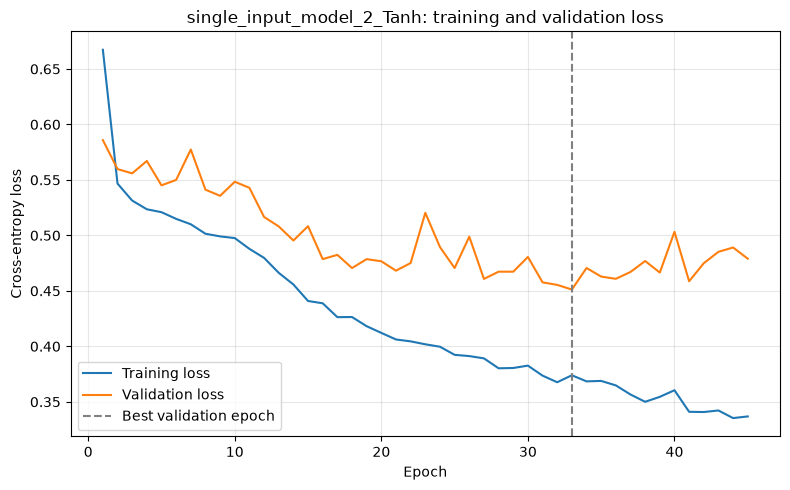

In [ ]:
# Train single_input_model_2_Tanh to convergence

single_input_model_2_Tanh, single_input_model_2_Tanh_history = fit_to_convergence(
    single_input_model_2_Tanh,
    train_dataset_single,
    val_dataset_single,
    "single_input_model_2_Tanh",
)

single_input_model_4_ReLU | epoch 001 | train loss 0.9420 | validation loss 0.6849
single_input_model_4_ReLU | epoch 002 | train loss 0.5897 | validation loss 0.5524
single_input_model_4_ReLU | epoch 003 | train loss 0.5172 | validation loss 0.5337
single_input_model_4_ReLU | epoch 004 | train loss 0.4744 | validation loss 0.4918
single_input_model_4_ReLU | epoch 005 | train loss 0.4515 | validation loss 0.4806
single_input_model_4_ReLU | epoch 006 | train loss 0.4279 | validation loss 0.5012
single_input_model_4_ReLU | epoch 007 | train loss 0.4129 | validation loss 0.4691
single_input_model_4_ReLU | epoch 008 | train loss 0.3920 | validation loss 0.4747
single_input_model_4_ReLU | epoch 009 | train loss 0.3880 | validation loss 0.4685
single_input_model_4_ReLU | epoch 010 | train loss 0.3780 | validation loss 0.4751
single_input_model_4_ReLU | epoch 011 | train loss 0.3537 | validation loss 0.4780
single_input_model_4_ReLU | epoch 012 | train loss 0.3478 | validation loss 0.4655
sing

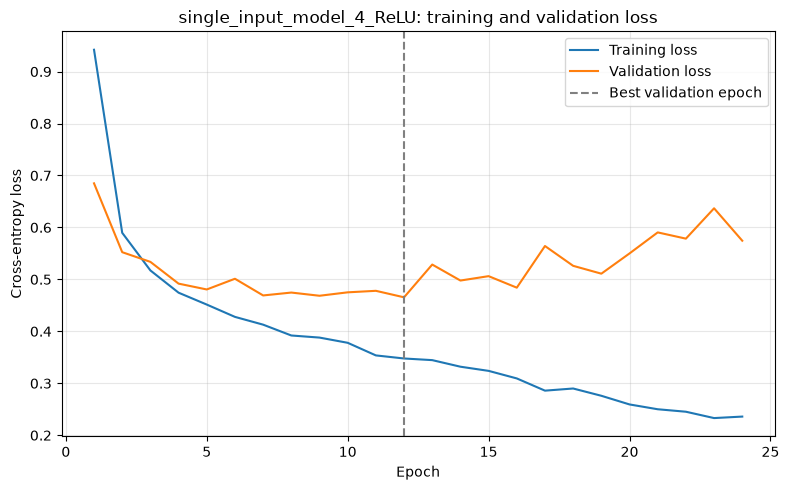

In [38]:
# Train single_input_model_4_ReLU to convergence

single_input_model_4_ReLU, single_input_model_4_ReLU_history = fit_to_convergence(
    single_input_model_4_ReLU,
    train_dataset_single,
    val_dataset_single,
    "single_input_model_4_ReLU",
)

single_input_model_4_Tanh | epoch 001 | train loss 0.7019 | validation loss 0.5998
single_input_model_4_Tanh | epoch 002 | train loss 0.5540 | validation loss 0.5604
single_input_model_4_Tanh | epoch 003 | train loss 0.5341 | validation loss 0.5553
single_input_model_4_Tanh | epoch 004 | train loss 0.5254 | validation loss 0.5509
single_input_model_4_Tanh | epoch 005 | train loss 0.5210 | validation loss 0.5373
single_input_model_4_Tanh | epoch 006 | train loss 0.5091 | validation loss 0.5433
single_input_model_4_Tanh | epoch 007 | train loss 0.4970 | validation loss 0.5245
single_input_model_4_Tanh | epoch 008 | train loss 0.4945 | validation loss 0.5355
single_input_model_4_Tanh | epoch 009 | train loss 0.4770 | validation loss 0.5192
single_input_model_4_Tanh | epoch 010 | train loss 0.4716 | validation loss 0.5012
single_input_model_4_Tanh | epoch 011 | train loss 0.4627 | validation loss 0.5059
single_input_model_4_Tanh | epoch 012 | train loss 0.4603 | validation loss 0.5156
sing

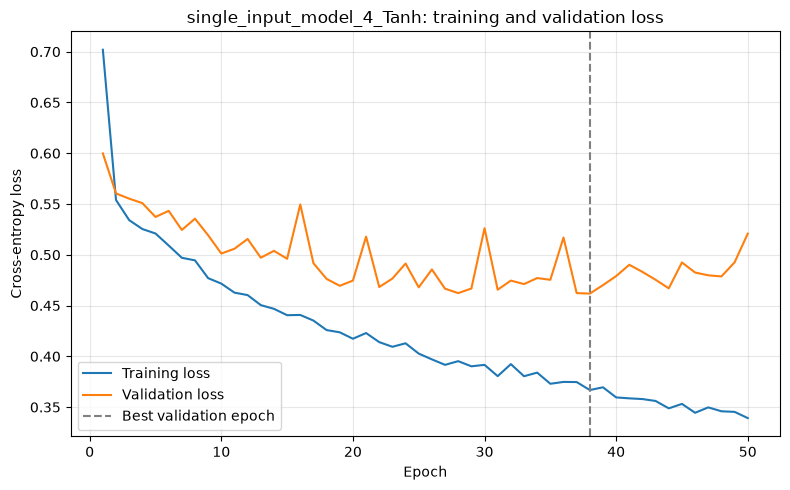

In [39]:
# Train single_input_model_4_Tanh to convergence

single_input_model_4_Tanh, single_input_model_4_Tanh_history = fit_to_convergence(
    single_input_model_4_Tanh,
    train_dataset_single,
    val_dataset_single,
    "single_input_model_4_Tanh",
)

multi_modal_model_2_ReLU | epoch 001 | train loss 0.7544 | validation loss 0.6055
multi_modal_model_2_ReLU | epoch 002 | train loss 0.5681 | validation loss 0.5659
multi_modal_model_2_ReLU | epoch 003 | train loss 0.5197 | validation loss 0.5086
multi_modal_model_2_ReLU | epoch 004 | train loss 0.4743 | validation loss 0.5045
multi_modal_model_2_ReLU | epoch 005 | train loss 0.4565 | validation loss 0.4834
multi_modal_model_2_ReLU | epoch 006 | train loss 0.4476 | validation loss 0.4782
multi_modal_model_2_ReLU | epoch 007 | train loss 0.4358 | validation loss 0.4858
multi_modal_model_2_ReLU | epoch 008 | train loss 0.4234 | validation loss 0.5204
multi_modal_model_2_ReLU | epoch 009 | train loss 0.4218 | validation loss 0.4656
multi_modal_model_2_ReLU | epoch 010 | train loss 0.4173 | validation loss 0.4923
multi_modal_model_2_ReLU | epoch 011 | train loss 0.4103 | validation loss 0.4524
multi_modal_model_2_ReLU | epoch 012 | train loss 0.4020 | validation loss 0.4569
multi_modal_mode

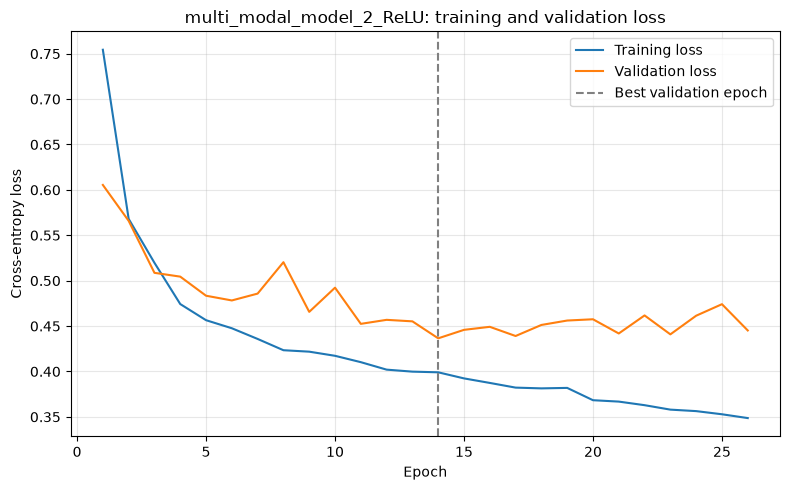

In [40]:
# Train multi_modal_model_2_ReLU to convergence

multi_modal_model_2_ReLU, multi_modal_model_2_ReLU_history = fit_to_convergence(
    multi_modal_model_2_ReLU,
    train_dataset_parallel,
    val_dataset_parallel,
    "multi_modal_model_2_ReLU",
)

multi_modal_model_2_Tanh | epoch 001 | train loss 0.6722 | validation loss 0.6047
multi_modal_model_2_Tanh | epoch 002 | train loss 0.5627 | validation loss 0.5584
multi_modal_model_2_Tanh | epoch 003 | train loss 0.5347 | validation loss 0.5636
multi_modal_model_2_Tanh | epoch 004 | train loss 0.5213 | validation loss 0.5504
multi_modal_model_2_Tanh | epoch 005 | train loss 0.5063 | validation loss 0.5300
multi_modal_model_2_Tanh | epoch 006 | train loss 0.4945 | validation loss 0.5281
multi_modal_model_2_Tanh | epoch 007 | train loss 0.4859 | validation loss 0.5313
multi_modal_model_2_Tanh | epoch 008 | train loss 0.4813 | validation loss 0.5184
multi_modal_model_2_Tanh | epoch 009 | train loss 0.4728 | validation loss 0.5180
multi_modal_model_2_Tanh | epoch 010 | train loss 0.4678 | validation loss 0.5015
multi_modal_model_2_Tanh | epoch 011 | train loss 0.4594 | validation loss 0.5066
multi_modal_model_2_Tanh | epoch 012 | train loss 0.4575 | validation loss 0.4980
multi_modal_mode

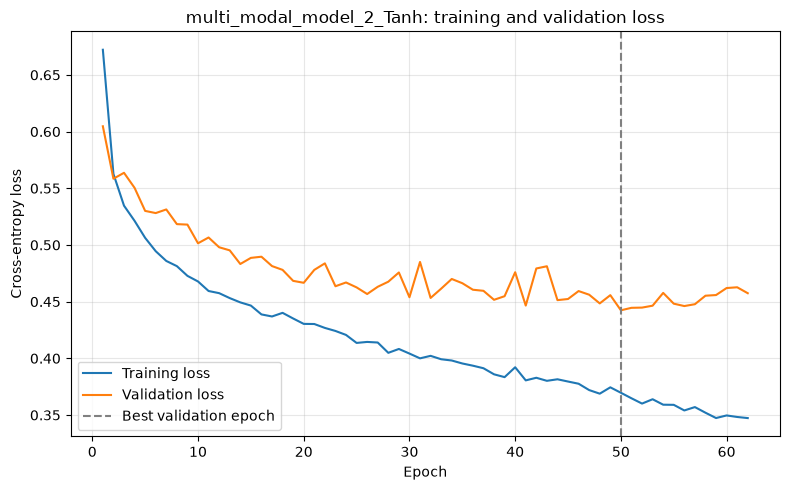

In [42]:
# Train multi_modal_model_2_Tanh to convergence

multi_modal_model_2_Tanh, multi_modal_model_2_Tanh_history = fit_to_convergence(
    multi_modal_model_2_Tanh,
    train_dataset_parallel,
    val_dataset_parallel,
    "multi_modal_model_2_Tanh",
)

multi_modal_model_4_ReLU | epoch 001 | train loss 0.8809 | validation loss 0.6829
multi_modal_model_4_ReLU | epoch 002 | train loss 0.6099 | validation loss 0.5772
multi_modal_model_4_ReLU | epoch 003 | train loss 0.5288 | validation loss 0.5163
multi_modal_model_4_ReLU | epoch 004 | train loss 0.4828 | validation loss 0.5029
multi_modal_model_4_ReLU | epoch 005 | train loss 0.4616 | validation loss 0.5231
multi_modal_model_4_ReLU | epoch 006 | train loss 0.4483 | validation loss 0.5550
multi_modal_model_4_ReLU | epoch 007 | train loss 0.4376 | validation loss 0.4779
multi_modal_model_4_ReLU | epoch 008 | train loss 0.4261 | validation loss 0.4647
multi_modal_model_4_ReLU | epoch 009 | train loss 0.4301 | validation loss 0.4789
multi_modal_model_4_ReLU | epoch 010 | train loss 0.4241 | validation loss 0.4749
multi_modal_model_4_ReLU | epoch 011 | train loss 0.4034 | validation loss 0.4608
multi_modal_model_4_ReLU | epoch 012 | train loss 0.4029 | validation loss 0.4644
multi_modal_mode

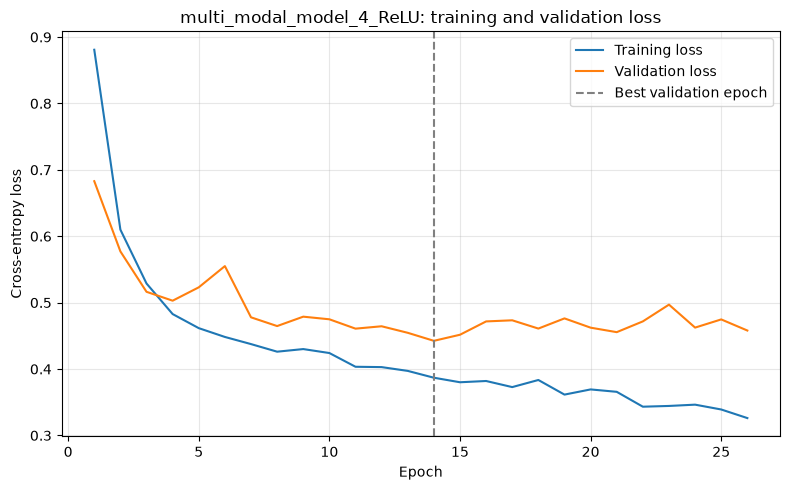

In [41]:
# Train multi_modal_model_4_ReLU to convergence

multi_modal_model_4_ReLU, multi_modal_model_4_ReLU_history = fit_to_convergence(
    multi_modal_model_4_ReLU,
    train_dataset_parallel,
    val_dataset_parallel,
    "multi_modal_model_4_ReLU",
)

multi_modal_model_4_Tanh | epoch 001 | train loss 0.7338 | validation loss 0.5858
multi_modal_model_4_Tanh | epoch 002 | train loss 0.5556 | validation loss 0.5688
multi_modal_model_4_Tanh | epoch 003 | train loss 0.5289 | validation loss 0.5527
multi_modal_model_4_Tanh | epoch 004 | train loss 0.5176 | validation loss 0.5277
multi_modal_model_4_Tanh | epoch 005 | train loss 0.5033 | validation loss 0.5599
multi_modal_model_4_Tanh | epoch 006 | train loss 0.4907 | validation loss 0.5148
multi_modal_model_4_Tanh | epoch 007 | train loss 0.4868 | validation loss 0.5400
multi_modal_model_4_Tanh | epoch 008 | train loss 0.4737 | validation loss 0.5110
multi_modal_model_4_Tanh | epoch 009 | train loss 0.4620 | validation loss 0.4834
multi_modal_model_4_Tanh | epoch 010 | train loss 0.4611 | validation loss 0.5075
multi_modal_model_4_Tanh | epoch 011 | train loss 0.4496 | validation loss 0.4991
multi_modal_model_4_Tanh | epoch 012 | train loss 0.4444 | validation loss 0.4851
multi_modal_mode

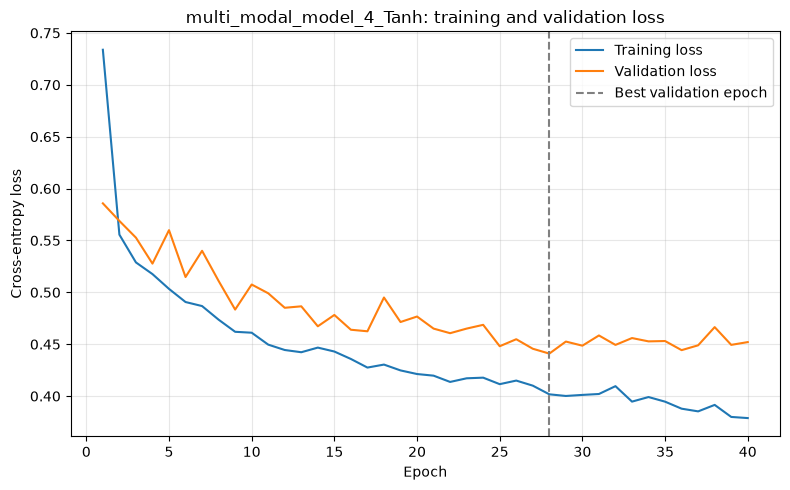

In [43]:
# Train multi_modal_model_4_Tanh to convergence

multi_modal_model_4_Tanh, multi_modal_model_4_Tanh_history = fit_to_convergence(
    multi_modal_model_4_Tanh,
    train_dataset_parallel,
    val_dataset_parallel,
    "multi_modal_model_4_Tanh",
)

## Model Evaluation
Evaluate the best performing network using (1) an appropriate evaluation metric such as Accuracy / Precision / Recall / F1, and (2) Confusion Matrices. You may also use the loss curves from the previous section for model evaluation.  Teams may use an LLM to generate visualization code. For at least one visualization, teams should:

- prompt an LLM to interpret the results based upon the visualization
- identify one useful insight
- identify one overly generic, incorrect, or unsupported conclusion
- provide the final interpretation in your own words

*Prompt:* 

Agent used: Microsoft Copilot GPT 6 - Luna

**LLM Output:** 

### Answer the following questions
Which architectural change had the greatest impact?

Which training parameter had the greatest impact?

What surprised you most?

How useful was the LLM during this assignment?

Where did the LLM make mistakes, if any?

## Exceptional Work
Provide additional analysis extending your investigation.

We wanted to see the effects of using a different optimizer from the eight we had created. 